In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Importing csv dataset
branches = pd.read_csv("C:/Users/HP/Documents/projects/My_Project_Mawiz/raw_data/PrimeMart_Retail_Analytics_Datasets/branches.csv")
categories = pd.read_csv("C:/Users/HP/Documents/projects/My_Project_Mawiz/raw_data/PrimeMart_Retail_Analytics_Datasets/categories.csv")
customers = pd.read_csv("C:/Users/HP/Documents/projects/My_Project_Mawiz/raw_data/PrimeMart_Retail_Analytics_Datasets/customers.csv")
employees = pd.read_csv("C:/Users/HP/Documents/projects/My_Project_Mawiz/raw_data/PrimeMart_Retail_Analytics_Datasets/employees.csv")
inventory = pd.read_csv("C:/Users/HP/Documents/projects/My_Project_Mawiz/raw_data/PrimeMart_Retail_Analytics_Datasets/inventory.csv")
products = pd.read_csv("C:/Users/HP/Documents/projects/My_Project_Mawiz/raw_data/PrimeMart_Retail_Analytics_Datasets/products.csv")
sale_items = pd.read_csv("C:/Users/HP/Documents/projects/My_Project_Mawiz/raw_data/PrimeMart_Retail_Analytics_Datasets/sale_items.csv")
sales = pd.read_csv("C:/Users/HP/Documents/projects/My_Project_Mawiz/raw_data/PrimeMart_Retail_Analytics_Datasets/sales.csv")
suppliers = pd.read_csv("C:/Users/HP/Documents/projects/My_Project_Mawiz/raw_data/PrimeMart_Retail_Analytics_Datasets/suppliers.csv")


In [2]:

# Coverting date to pandas(pd) standard datetime
sales["sale_date"] = pd.to_datetime(sales["sale_date"])
sales["year_month"] = sales["sale_date"].dt.to_period('M')
sales["year"] = sales["sale_date"].dt.year
sales["month name"] = sales["sale_date"].dt.month_name()

In [3]:
# merging the tables for relational model
df = sale_items.merge(sales, on='sale_id', how='left')
df = df.merge(products, on='product_id', how='left')
df = df.merge(branches, on='branch_id', how='left')
df = df.merge(customers, on='customer_id', how='left')
df = df.merge(categories, on='category_id', how='left')
df = df.merge(employees, on='employee_id', how='left')


In [4]:
# Executive Financial Core Performance
print("=== EXECUTIVE FINANCIAL CORE PERFORMANCE ====")
tot_rev = (df['unit_price'] * df['quantity']).sum()
tot_disc = round(df['discount'].sum(), 2)
net_rev = tot_rev - tot_disc
tot_cst = (df['unit_cost_x'] * df['quantity']).sum()
gross_prof = net_rev - tot_cst
gross_marg = round((gross_prof / net_rev) * 100, 2)
print(f"""Total Revenue: ${tot_rev:,.2f}
Total Discount: ${tot_disc:,.2f}
Total Cost: ${tot_cst:,.2f}
Net Revenue: ${net_rev:,.2f}
Gross Profit: ${gross_prof:,.2f}
Gross Margin: {gross_marg:,.2f}%""")

=== EXECUTIVE FINANCIAL CORE PERFORMANCE ====
Total Revenue: $42,025,128,830.82
Total Discount: $1,023,481,023.33
Total Cost: $32,689,601,414.29
Net Revenue: $41,001,647,807.49
Gross Profit: $8,312,046,393.20
Gross Margin: 20.27%


In [5]:
# Add the core finacial metrics to the master dataframe
df['total_revenue'] = df['unit_price'] * df['quantity']
df ['net_revenue'] = df['total_revenue'] - df['discount']
df['total_cost'] = df['unit_cost_x'] * df['quantity']
df['gross_profit'] = df['net_revenue'] - df['total_cost']


In [15]:
print("=== MONTH-OVER-MONTH PERFORMANCE DRIFT ===")

# 1. Group by month and pull core financial metrics
m_perf = df.groupby('month name').agg(
    net_revenue = ('net_revenue', 'sum'),
    gross_profit = ('gross_profit', 'sum')
)

# 2. Calculate growth and margin percentages
m_perf['gross_margin_%'] = (m_perf['gross_profit'] / m_perf['net_revenue']) *100
m_perf['net_rev_growth_%'] = m_perf['net_revenue'].pct_change() * 100
m_perf['profit_growth_%'] = m_perf['gross_profit'].pct_change() * 100

# 3. Sort by Gross Profit descending

print("MOnthly Trend by Net Revenue & Gross Profit:\n",m_perf.sort_values('gross_profit',ascending=False))


print("\n"+"="*40)







print("=== REGIONAL BRANCH RANKING ===")
# Grouping by branch to fetch generated net revenue and gross profit
b_perf = df.groupby('branch_name').agg(
    net_revenue = ('net_revenue', 'sum'),
    gross_profit = ('gross_profit', 'sum')
)
print("Top 5 Branch by Net Revenue & Gross Profit:\n",b_perf.sort_values('net_revenue',ascending=False).head(10))

print("\n"+"="*40)




print("\n=== PRODUCT & CATEGORY INTELLIGENCE ===")
# Category Ppreformance
cat_perf = df.groupby('category_name').agg(
    net_revenue = ('net_revenue', 'sum'),
    gross_profit = ('gross_profit', 'sum')
)

print("Category Contribution:\n", cat_perf.sort_values('gross_profit',ascending=False))



# Product Performance
p_perf = df.groupby('product_name').agg(
    volume = ('quantity', 'sum'),
    net_revenue = ('net_revenue', 'sum'),
    gross_profit = ('gross_profit', 'sum')
)

print("\nTop 5 Moving Products(Volume):\n",p_perf.sort_values('volume',ascending=False).head(5))
print("\nTop 5 Most Profitable Products:\n",p_perf.sort_values('gross_profit',ascending=False).head(5))

print("\n"+"="*40)



print("\n===: EMPLOYEE SALES CONTRIBUTION ===")

e_perf = df.groupby('employee_name').agg(
    net_revenue = ('net_revenue', 'sum')
)
print(e_perf.sort_values('net_revenue',ascending=False).head(10))
print("\n"+"="*40)




print("\n===: CUSTOMER CONCENTRATION ===")
# Customer Segment Performance

seg_perf = df.groupby('customer_segment').agg(
    net_revenue = ('net_revenue', 'sum'),
    gross_profit = ('gross_profit', 'sum')
)
print("Customer Segment Insight:\n",seg_perf.sort_values('gross_profit',ascending=False))



# Top 5 Individual Customers(Sorted by Total Revenue)
top_cust = df.groupby(['customer_id', 'first_name', 'last_name' ])['total_revenue'].sum()

print("\nTop 5 Highest Value Individual Customers:\n",top_cust.sort_values(ascending=False).head(5))

print("\n"+"="*40)



print("\n==== RFM LIFETIME VALUES ===")

ref_date = sales['sale_date'].max() + pd.Timedelta(days=1)
rfm = df.groupby('customer_id').agg(
    Recency = ('sale_date', lambda x: (ref_date - x.max()).days),
    Frequency = ('sale_id', 'nunique'),
    Monetary = ('total_revenue', 'sum')
)

at_risk = rfm[rfm['Recency'] > 180]
at_risk_ids =  rfm[rfm['Recency'] > 180].index
at_risk_list = df[df['customer_id'].isin(at_risk_ids)][['customer_id', 'first_name', 'last_name']].drop_duplicates()
print(f"Customers flagged at-risk (Inactive > 180 Days): {len(at_risk_list)}")
display(at_risk_list)
print("\n"+"="*40)




print("\n=== TRANSACTION CHANNEL & PAYMENT METHOD ====")

payment_method = df.groupby('payment_method').agg(
    count = ('sale_id', 'nunique')
).reset_index()
payment_method = payment_method.sort_values(by='count',ascending=False)
  

sale_channel = df.groupby('sales_channel').agg(
    count = ('sale_id', 'nunique')
).reset_index()
sale_channel = sale_channel.sort_values(by='count',ascending=False)



print("\nMost Used Payment Methods:")
display(payment_method)
      
print("\nMost Popular Selling Channels:") 
display(sale_channel)


=== MONTH-OVER-MONTH PERFORMANCE DRIFT ===
MOnthly Trend by Net Revenue & Gross Profit:
              net_revenue  gross_profit  gross_margin_%  net_rev_growth_%  \
month name                                                                 
May         3.549804e+09  7.247161e+08       20.415663          2.158571   
August      3.504211e+09  7.137809e+08       20.369237          4.937542   
October     3.495106e+09  7.073442e+08       20.238133          4.323502   
December    3.477152e+09  7.049807e+08       20.274659         -0.772172   
July        3.488125e+09  7.038429e+08       20.178257          0.658828   
March       3.474798e+09  7.033947e+08       20.242747          3.356780   
January     3.465295e+09  7.018051e+08       20.252392         10.365399   
June        3.361945e+09  6.805230e+08       20.241941         -3.617416   
April       3.339330e+09  6.798471e+08       20.358789               NaN   
November    3.350258e+09  6.798113e+08       20.291314         -5.621347   

,customer_id,first_name,last_name
403,C01075,Joy,Okafor
3668,C04256,Victor,Okeke
3802,C04982,Chioma,Iroha
4876,C04449,Obinna,Eze
6168,C03651,Precious,Umeh
6486,C01007,Ngozi,Eze
6855,C02535,Samuel,Onyeka
7187,C02538,Ada,Chukwu
8287,C01371,Michael,Nwosu
8374,C03671,Kelechi,Obi




=== TRANSACTION CHANNEL & PAYMENT METHOD ====

Most Used Payment Methods:


,payment_method,count
3,POS,38061
4,Transfer,21988
1,Cash,15947
0,Card,12104
2,Online Payment,11900



Most Popular Selling Channels:


,sales_channel,count
1,Store,78026
0,Online,21974


In [7]:
df.columns

Index(['sale_item_id', 'sale_id', 'product_id', 'quantity', 'unit_price',
       'discount', 'unit_cost_x', 'sale_date', 'customer_id', 'branch_id_x',
       'employee_id', 'payment_method', 'sales_channel', 'discount_amount',
       'tax_amount', 'shipping_cost', 'order_status', 'year_month', 'year',
       'month name', 'product_name', 'category_id', 'supplier_id',
       'unit_cost_y', 'selling_price', 'reorder_level', 'product_status',
       'branch_name', 'city_x', 'state_x', 'region', 'opening_date',
       'branch_manager', 'first_name', 'last_name', 'gender', 'date_of_birth',
       'city_y', 'state_y', 'customer_segment', 'registration_date',
       'category_name', 'department', 'employee_name', 'branch_id_y',
       'job_role', 'hire_date', 'employment_status', 'total_revenue',
       'net_revenue', 'total_cost', 'gross_profit'],
      dtype='object')

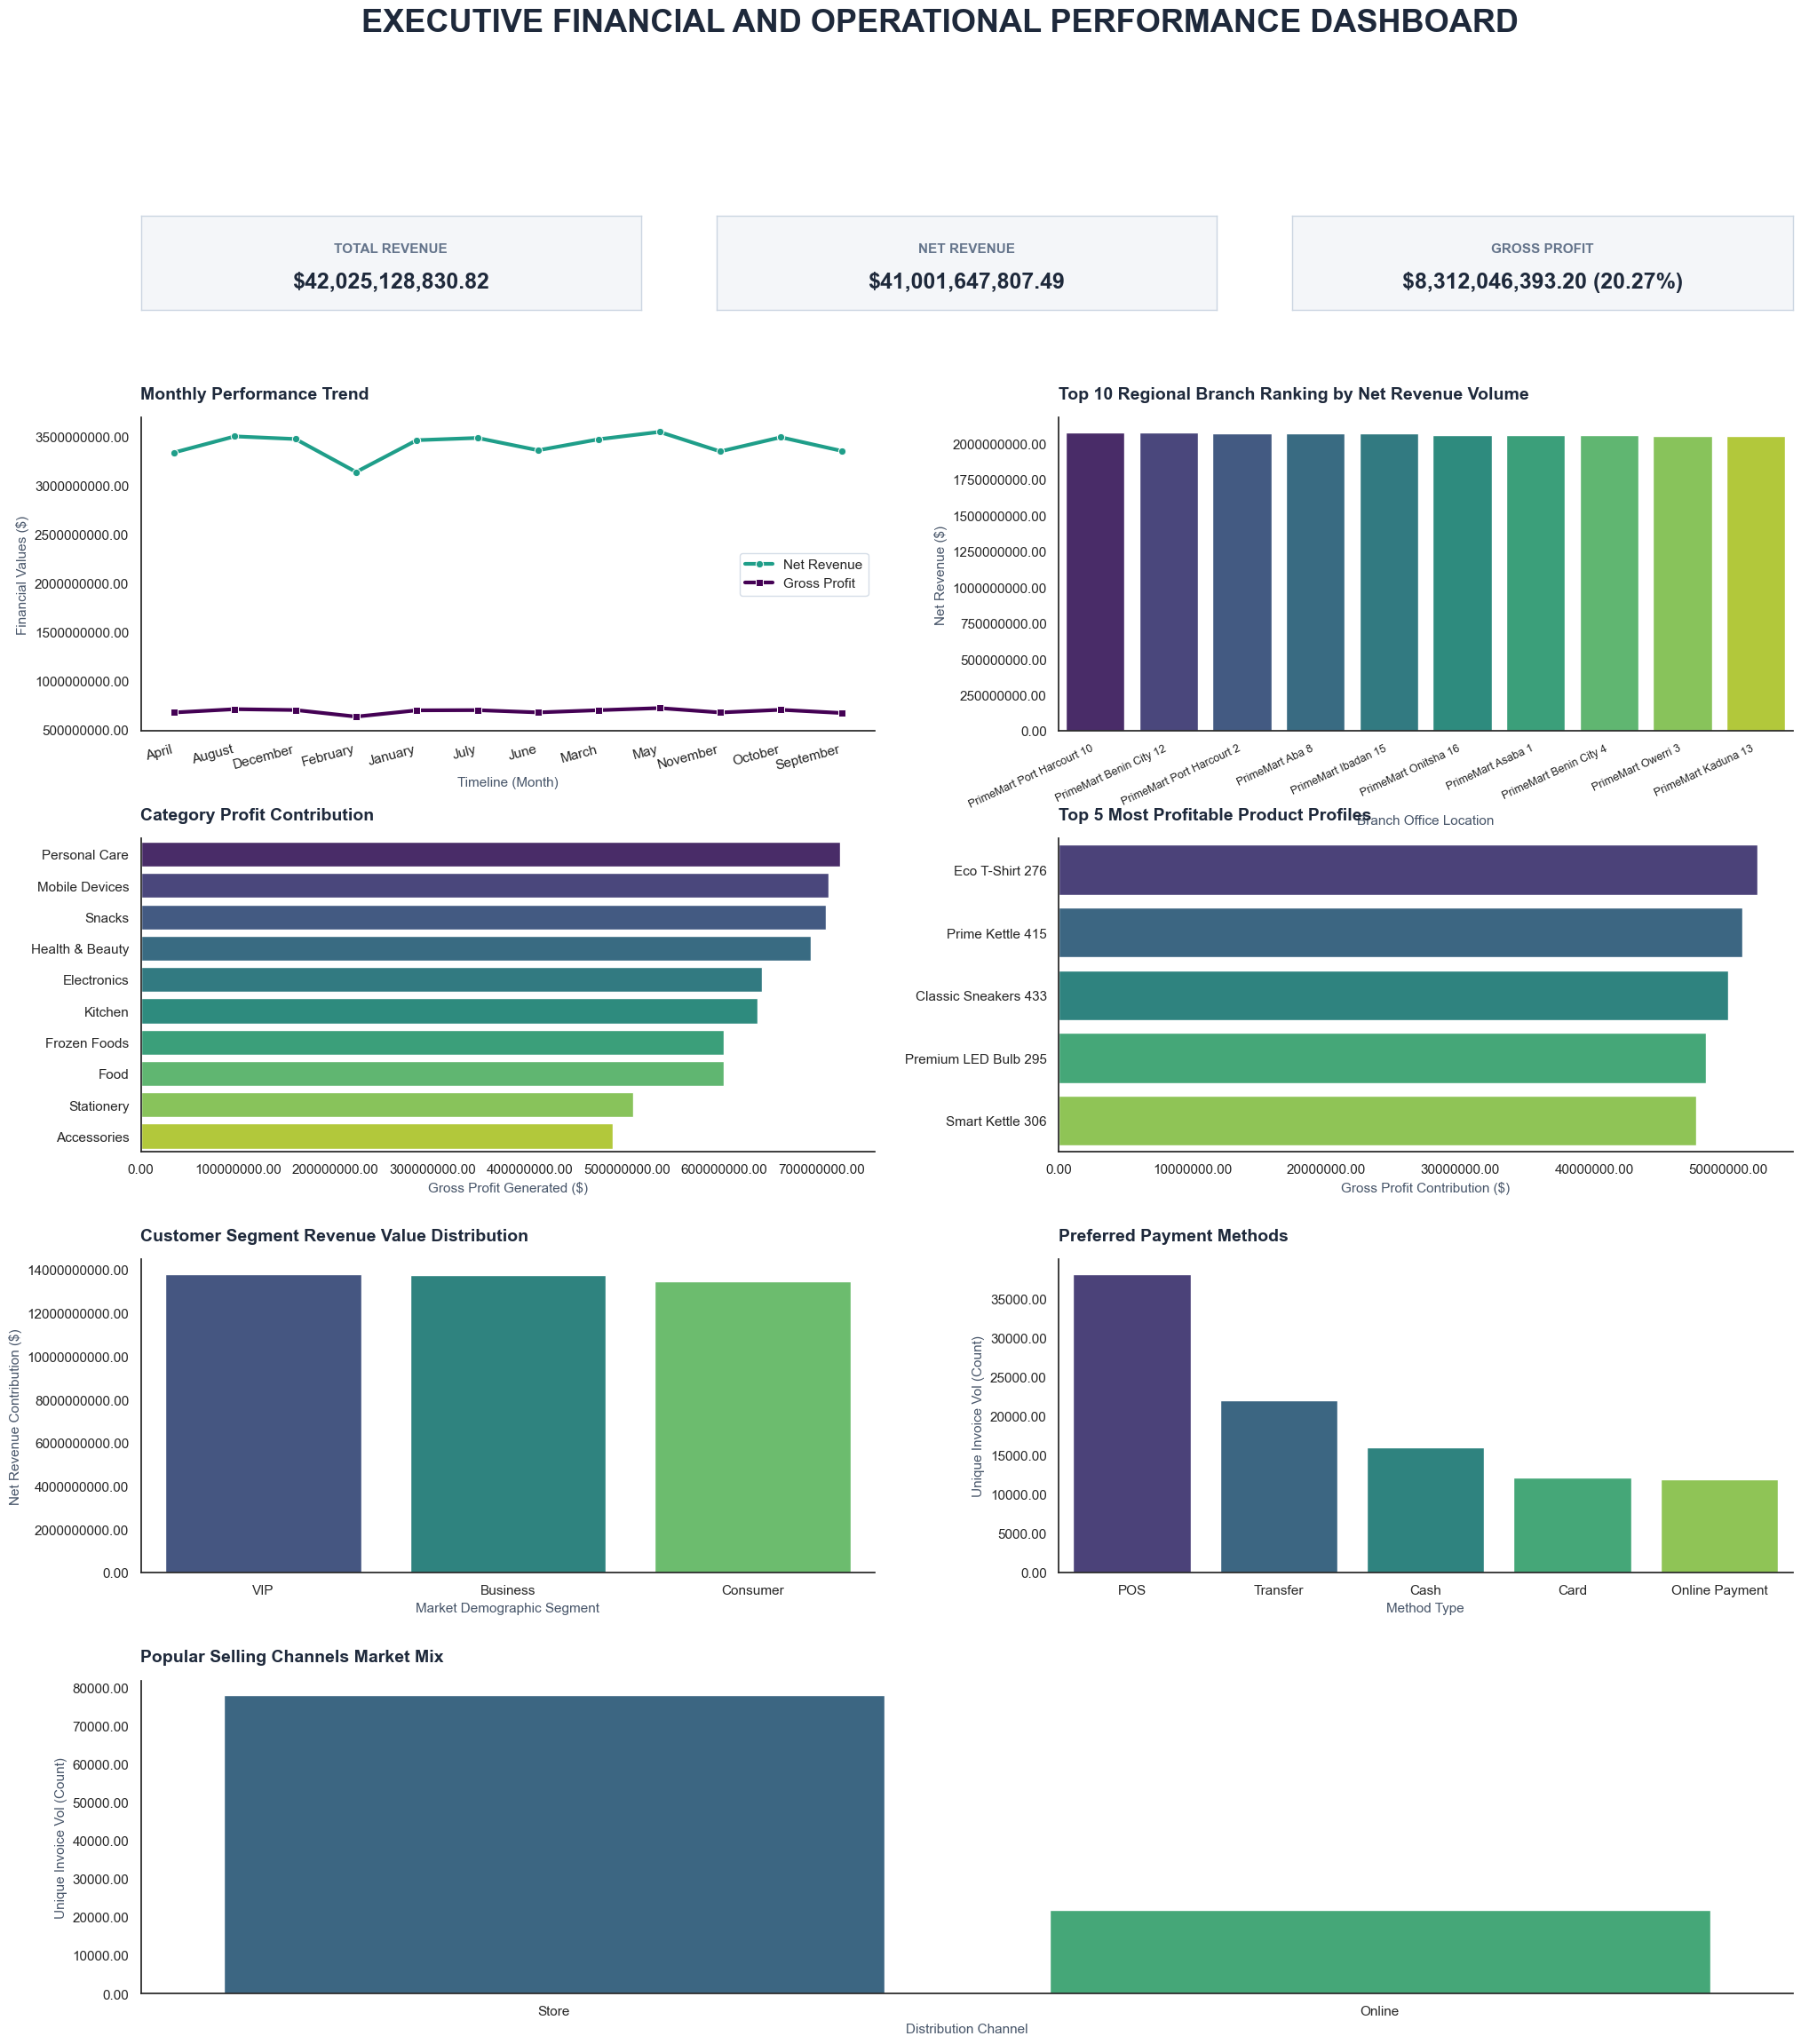

In [33]:

# Canvas Style Configuration
sns.set_theme(style='white')
plt.rcParams['font.family'] = 'sans-serif'

# Define corporate palette
kpi_bg = '#f4f6f9'
text_dark = '#1e293b'
primary_hue = 'viridis'

# CREATE CANVAS WORKSPACE LAYOUT
# Shifted to a highly efficient 5-row by 2-column configuration grid layout
fig = plt.figure(figsize=(24, 26), facecolor='#ffffff')
gs = plt.GridSpec(5, 2, figure=fig, height_ratios=[0.3, 1, 1, 1, 1], hspace=0.4, wspace=0.25)

fig.suptitle("EXECUTIVE FINANCIAL AND OPERATIONAL PERFORMANCE DASHBOARD",
             fontsize=26, fontweight='bold', color=text_dark, y=0.97)

# ==========================================
# ROW 0: TOP KPI PERFORMANCE STRIP (Merged Columns dynamically)
# ==========================================
kpis = [
    {"label": "TOTAL REVENUE", "val": f"${tot_rev:,.2f}"},
    {"label": "NET REVENUE", "val": f"${net_rev:,.2f}"},
    {"label": "GROSS PROFIT", "val": f"${gross_prof:,.2f} ({gross_marg:,.2f}%)"}
]

# Distribute 3 KPI blocks evenly using a nested sub-gridspec grid layout
gs_kpi = gs[0, :].subgridspec(1, 3, wspace=0.15)
for idx, kpi in enumerate(kpis):
    ax_kpi = fig.add_subplot(gs_kpi[0, idx])
    ax_kpi.set_facecolor(kpi_bg)
    
    # Draw simple slate border outlines
    for spine in ax_kpi.spines.values():
        spine.set_edgecolor('#cbd5e1')
        spine.set_linewidth(1)
        
    ax_kpi.get_xaxis().set_visible(False)
    ax_kpi.get_yaxis().set_visible(False)
    
    ax_kpi.text(0.5, 0.65, kpi["label"], fontsize=11, fontweight='bold', color='#64748b', ha='center', va='center')
    ax_kpi.text(0.5, 0.30, kpi["val"], fontsize=18, fontweight='bold', color=text_dark, ha='center', va='center')


# ==========================================
# ROW 1: TRENDS & REGIONAL RANKINGS (SIDE-BY-SIDE)
# ==========================================
# LEFT: Monthly Trend Line Chart
ax1 = fig.add_subplot(gs[1, 0])
sns.lineplot(data=m_perf, x=m_perf.index.astype(str), y='net_revenue',
             ax=ax1, marker='o', linewidth=3, color='#1f9e89', label='Net Revenue')
sns.lineplot(data=m_perf, x=m_perf.index.astype(str), y='gross_profit',
             ax=ax1, marker='s', linewidth=3, color='#440154', label='Gross Profit')
ax1.set_title("Monthly Performance Trend", fontsize=14, fontweight='bold', color=text_dark, loc='left', pad=15)
ax1.set_xlabel("Timeline (Month)", fontsize=11, color='#475569')
ax1.set_ylabel("Financial Values ($)", fontsize=11, color='#475569')
ax1.yaxis.set_major_formatter(plt.FormatStrFormatter('%.2f'))
plt.setp(ax1.get_xticklabels(), rotation=15, ha="right")
ax1.legend(frameon=True, facecolor='#ffffff', edgecolor='#cbd5e1')
sns.despine(ax=ax1)

# RIGHT: Regional Branch Performance Ranking
ax2 = fig.add_subplot(gs[1, 1])
b_perf_sorted = b_perf.sort_values(by='net_revenue', ascending=False).reset_index().head(10)
sns.barplot(data=b_perf_sorted, x='branch_name', y='net_revenue', ax=ax2, palette=primary_hue, hue='branch_name', legend=False)
ax2.set_title("Top 10 Regional Branch Ranking by Net Revenue Volume", fontsize=14, fontweight='bold', color=text_dark, loc='left', pad=15)
ax2.set_xlabel("Branch Office Location", fontsize=11, color='#475569')
ax2.set_ylabel("Net Revenue ($)", fontsize=11, color='#475569')
ax2.yaxis.set_major_formatter(plt.FormatStrFormatter('%.2f'))  # Fixed copy-paste ax1 axis assignment bug
plt.setp(ax2.get_xticklabels(), rotation=25, ha="right", fontsize=9)
sns.despine(ax=ax2)


# ==========================================
# ROW 2: CATEGORY & PRODUCT PROFITABILITY (SIDE-BY-SIDE)
# ==========================================
# LEFT: Category Profits Breakdown
ax3 = fig.add_subplot(gs[2, 0])
cat_perf_sorted = cat_perf.sort_values(by='gross_profit', ascending=False).reset_index().head(10)
sns.barplot(data=cat_perf_sorted, y='category_name', x='gross_profit', ax=ax3, palette=primary_hue, hue='category_name', legend=False)
ax3.set_title("Category Profit Contribution", fontsize=14, fontweight='bold', color=text_dark, loc='left', pad=15)
ax3.set_ylabel("", fontsize=11)
ax3.set_xlabel("Gross Profit Generated ($)", fontsize=11, color='#475569')
ax3.xaxis.set_major_formatter(plt.FormatStrFormatter('%.2f'))
sns.despine(ax=ax3)

# RIGHT: Top 5 Most Profitable Individual Products
ax4 = fig.add_subplot(gs[2, 1])
p_perf_sorted = p_perf.sort_values(by='gross_profit', ascending=False).head(5).reset_index()
sns.barplot(data=p_perf_sorted, x='gross_profit', y='product_name', ax=ax4, palette=primary_hue, hue='product_name', legend=False)
ax4.set_title("Top 5 Most Profitable Product Profiles", fontsize=14, fontweight='bold', color=text_dark, loc='left', pad=15)
ax4.set_ylabel("", fontsize=11)
ax4.set_xlabel("Gross Profit Contribution ($)", fontsize=11, color='#475569')
ax4.xaxis.set_major_formatter(plt.FormatStrFormatter('%.2f'))
sns.despine(ax=ax4)


# ==========================================
# ROW 3: SEGMENT DEMOGRAPHICS & INVOICING METHODS (SIDE-BY-SIDE)
# ==========================================
# LEFT: Customer Market Segment Volume
ax5 = fig.add_subplot(gs[3, 0])
seg_perf_sorted = seg_perf.sort_values(by='net_revenue', ascending=False).reset_index()
sns.barplot(data=seg_perf_sorted, x='customer_segment', y='net_revenue', ax=ax5, palette=primary_hue, hue='customer_segment', legend=False)
ax5.set_title("Customer Segment Revenue Value Distribution", fontsize=14, fontweight='bold', color=text_dark, loc='left', pad=15)
ax5.set_xlabel("Market Demographic Segment", fontsize=11, color='#475569')
ax5.set_ylabel("Net Revenue Contribution ($)", fontsize=11, color='#475569')
ax5.yaxis.set_major_formatter(plt.FormatStrFormatter('%.2f'))
sns.despine(ax=ax5)

# RIGHT: Preferred Operational Settlement Methods
ax6 = fig.add_subplot(gs[3, 1])
sns.barplot(data=payment_method, x='payment_method', y='count', ax=ax6, palette=primary_hue, hue='payment_method', legend=False)
ax6.set_title("Preferred Payment Methods", fontsize=14, fontweight='bold', color=text_dark, loc='left', pad=15)
ax6.set_xlabel("Method Type", fontsize=11, color='#475569')
ax6.set_ylabel("Unique Invoice Vol (Count)", fontsize=11, color='#475569')
ax6.yaxis.set_major_formatter(plt.FormatStrFormatter('%.2f'))
sns.despine(ax=ax6)


# ==========================================
# ROW 4: SALES CHANNEL MIX MIXTURE (FULL GRID WIDTH FOOTER BASE)
# ==========================================
ax7 = fig.add_subplot(gs[4, :])
sns.barplot(data=sale_channel, x='sales_channel', y='count', ax=ax7, palette=primary_hue, hue='sales_channel', legend=False)
ax7.set_title("Popular Selling Channels Market Mix", fontsize=14, fontweight='bold', color=text_dark, loc='left', pad=15)
ax7.set_xlabel("Distribution Channel", fontsize=11, color='#475569')
ax7.set_ylabel("Unique Invoice Vol (Count)", fontsize=11, color='#475569')
ax7.yaxis.set_major_formatter(plt.FormatStrFormatter('%.2f'))
sns.despine(ax=ax7)


# ==========================================
# EXPORT CONFIGURATION FOR CANVA WORKSPACE
# ==========================================
# Tighten layout grid bounding limits to prevent edge text clipping on save
plt.savefig('executive_dashboard_canva.png', dpi=300, bbox_inches='tight', transparent=False)
plt.show()



In [34]:
df.to_csv('C:/Users/HP/Documents/projects/My_Project_Mawiz/processed/my_project_mawiz.csv', index=False)